**EQUIPO DE TRABAJO**

1.   Hinsna Jurany Rincon Guerrero
2.   Ruth Catherin Rincon Guerrero
3.   Deivy Steve Varon Corredor
4.   Julio Andrés Silva Aragón
5.   Rigo Arvey Chapid Guacales


**Dataframe usada: UCI Predict Students Dropout**

# **PASO 1 y 2: Exploración y Gestión SQL / Preparación y Pipeline**


*   Cargar los datos con Pandas


In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report

In [97]:
# Cargar datos desde dataframe
data = pd.read_csv('data.csv', sep=';')

In [98]:
#Limpieza de nombres de columnas (eliminar espacios en blanco y tabulaciones ocultas)
data.columns = data.columns.str.strip()

In [99]:
# Visualizar dataframe (5 primeras filas del dataframe)
print("Primeras filas del archivo:\n", data.head())

Primeras filas del archivo:
    Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance  Previous qualification  \
0                           1                       1   
1                           1                       1   
2                           1                       1   
3                           1                       1   
4                           0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   
2        

In [100]:
# Resumen de información sobre el DataFrame
print("\nInformación del DataFrame:")
print(data.info())


Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qual

In [101]:
# Estadísticas descriptivas del DataFrame
print("\nEstadísticas descriptivas:")
print(data.describe())


Estadísticas descriptivas:
       Marital status  Application mode  Application order       Course  \
count     4424.000000       4424.000000        4424.000000  4424.000000   
mean         1.178571         18.669078           1.727848  8856.642631   
std          0.605747         17.484682           1.313793  2063.566416   
min          1.000000          1.000000           0.000000    33.000000   
25%          1.000000          1.000000           1.000000  9085.000000   
50%          1.000000         17.000000           1.000000  9238.000000   
75%          1.000000         39.000000           2.000000  9556.000000   
max          6.000000         57.000000           9.000000  9991.000000   

       Daytime/evening attendance  Previous qualification  \
count                 4424.000000             4424.000000   
mean                     0.890823                4.577758   
std                      0.311897               10.216592   
min                      0.000000                1.0

In [102]:
# Identificar valores faltantes
print("\nValores Faltantes:")
print(data.isnull().sum())


Valores Faltantes:
Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                          

In [103]:
# Ver cuántas filas duplicadas existen en total en el Dataframe original
print("Cantidad de duplicados:", data.duplicated().sum())

# Mostrar las filas que están repetidas
filas_duplicadas = data[data.duplicated(keep=False)]
print(filas_duplicadas)

Cantidad de duplicados: 0
Empty DataFrame
Columns: [Marital status, Application mode, Application order, Course, Daytime/evening attendance, Previous qualification, Previous qualification (grade), Nacionality, Mother's qualification, Father's qualification, Mother's occupation, Father's occupation, Admission grade, Displaced, Educational special needs, Debtor, Tuition fees up to date, Gender, Scholarship holder, Age at enrollment, International, Curricular units 1st sem (credited), Curricular units 1st sem (enrolled), Curricular units 1st sem (evaluations), Curricular units 1st sem (approved), Curricular units 1st sem (grade), Curricular units 1st sem (without evaluations), Curricular units 2nd sem (credited), Curricular units 2nd sem (enrolled), Curricular units 2nd sem (evaluations), Curricular units 2nd sem (approved), Curricular units 2nd sem (grade), Curricular units 2nd sem (without evaluations), Unemployment rate, Inflation rate, GDP, Target]
Index: []

[0 rows x 37 columns]


La DataFrame no cuenta con filas duplicadas

*  **Filtro IQR**

In [104]:
# Calcular los límites
Q1 = data['Age at enrollment'].quantile(0.25)
Q3 = data['Age at enrollment'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Contar cuántos outliers hay
outliers = data[(data['Age at enrollment'] < limite_inferior) | (data['Age at enrollment'] > limite_superior)]

print(f"Total de registros originales: {len(data)}")
print(f"Cantidad de estudiantes detectados como 'Atípicos' por edad: {len(outliers)}")
print(f"Porcentaje de datos atípicos: {(len(outliers)/len(data))*100:.2f}%")

Total de registros originales: 4424
Cantidad de estudiantes detectados como 'Atípicos' por edad: 441
Porcentaje de datos atípicos: 9.97%


OMITIMOS EL FILTRO IQR (Mantenemos los 4424 registros para no perder el 10%).

Realicé un análisis exploratorio mediante el método del Rango Intercuartílico (IQR) y detecté que el 9.97% de los estudiantes eran considerados atípicos por edad. Al ser un porcentaje tan alto, eliminarlos habría provocado un sesgo severo en el modelo, ignorando la realidad de la población de estudiantes adultos. Dado que los Árboles de Decisión manejan bien el sesgo de las variables, opté por mantenerlos para conservar la riqueza del dataset.

In [105]:
# 1. Filtrar y Excluir por completo a los estudiantes 'Enrolled' del DataFrame original
data = data[data['Target'] != 'Enrolled'].copy()

# 2. Definir el mapa de conversión binario limpio (Graduate = 1, Dropout = 0)
mapa_target = {'Graduate': 1, 'Dropout': 0}

# 3. Crear la nueva columna mapeando los valores en el DataFrame ya filtrado
data['Target_Binario'] = data['Target'].map(mapa_target)

# 4. Convertir la columna a tipo entero ('int') para garantizar que no tenga el decimal .0
data['Target_Binario'] = data['Target_Binario'].astype(int)

# --- Verificación de los cambios ---
print("Registros tras excluir 'Enrolled':", len(data))


Registros tras excluir 'Enrolled': 3630


Se excluyen los estudiantes matriculados (Enrolled) para centrar el análisis y el modelado exclusivamente en el desenlace final (Graduación vs. Deserción)

In [106]:
print("Primeras filas del archivo:\n", data.head(20))

Primeras filas del archivo:
     Marital status  Application mode  Application order  Course  \
0                1                17                  5     171   
1                1                15                  1    9254   
2                1                 1                  5    9070   
3                1                17                  2    9773   
4                2                39                  1    8014   
5                2                39                  1    9991   
6                1                 1                  1    9500   
7                1                18                  4    9254   
8                1                 1                  3    9238   
9                1                 1                  1    9238   
10               1                 1                  1    9670   
11               1                 1                  1    9500   
12               1                 1                  2    9853   
13               1               

In [107]:
# Buscar errores donde lo aprobado supere lo inscrito
inconsistencias = data[data['Curricular units 1st sem (approved)'] > data['Curricular units 1st sem (enrolled)']]
print(f"Filas con errores lógicos: {len(inconsistencias)}")

Filas con errores lógicos: 0


* **¿Influye la edad de matriculación en la deserción escolar?**


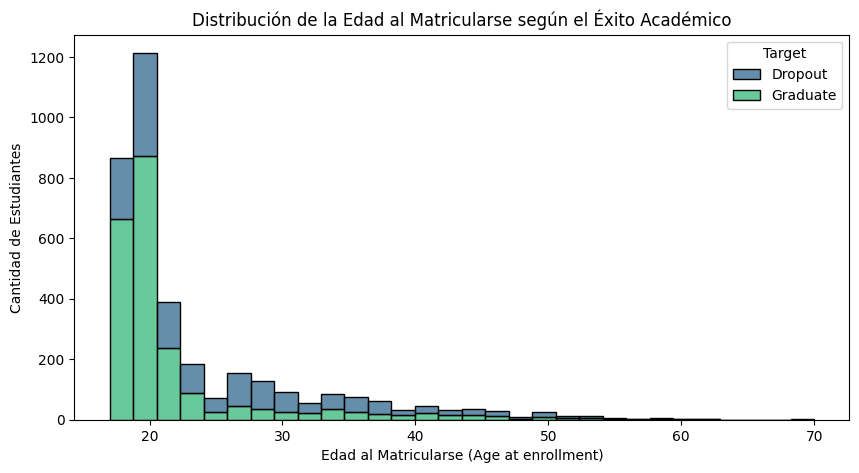

In [108]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='Age at enrollment', hue='Target', multiple='stack', bins=30, palette='viridis')
plt.title('Distribución de la Edad al Matricularse según el Éxito Académico')
plt.xlabel('Edad al Matricularse (Age at enrollment)')
plt.ylabel('Cantidad de Estudiantes')
plt.show()

Existe una relación inversa entre la edad de matriculación y el éxito académico. Mientras que los estudiantes que ingresan inmediatamente después de la educación media muestran las tasas de graduación más altas, el riesgo de abandono escolar se incrementa exponencialmente a mayor edad de inscripción. Esto sugiere la necesidad de implementar programas de apoyo y tutorías diferenciadas orientadas específicamente a los estudiantes de ingreso tardío o adultos, quienes enfrentan mayores barreras para culminar sus estudios.

*   **¿Existe una diferencia significativa en los promedios de calificaciones entre los alumnos que se gradúan y los que desertan?**


/tmp/ipykernel_576/3795106381.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Target', y='Curricular units 2nd sem (grade)', palette='Pastel1')


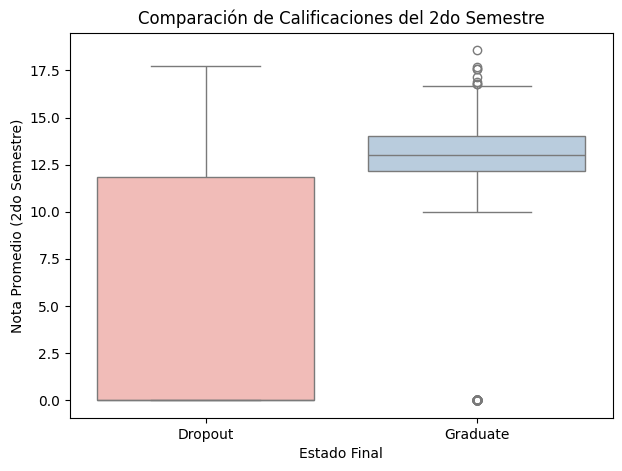

In [109]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x='Target', y='Curricular units 2nd sem (grade)', palette='Pastel1')
plt.title('Comparación de Calificaciones del 2do Semestre')
plt.xlabel('Estado Final')
plt.ylabel('Nota Promedio (2do Semestre)')
plt.show()

El gráfico demuestra que el rendimiento en el segundo semestre define el futuro del estudiante. Quienes se gradúan mantienen notas altas y estables (la mayoría entre 12 y 14), mientras que la gran mayoría de los que abandonan la carrera tienen un promedio de cero, lo que refleja que dejaron de asistir o no presentaron sus materias.

In [120]:
import sqlite3

# 1. Crear/Conectar a la base de datos local
conn = sqlite3.connect('universidad.db')
cursor = conn.cursor()

# 2. Guardar el dataframe limpio dentro de la base de datos SQL
# Si la tabla ya existe, la reemplaza
data.to_sql('estudiantes_limpio', conn, if_exists='replace', index=False)

# 3. Demostración de consulta eficiente (Ejemplo: Alumnos desertores mayores de 30 años)
query = """
SELECT Target, "Age at enrollment", "Curricular units 2nd sem (grade)"
FROM estudiantes_limpio
WHERE Target_Binario = 0 AND "Age at enrollment" > 30
LIMIT 5;
"""
df_consulta = pd.read_sql_query(query, conn)
print("Consulta SQL Ejecutada con Éxito (Muestra de Desertores > 30 años):\n", df_consulta)

# Cerrar la conexión temporalmente
conn.close()

Consulta SQL Ejecutada con Éxito (Muestra de Desertores > 30 años):
     Target  Age at enrollment  Curricular units 2nd sem (grade)
0  Dropout                 37                              10.0
1  Dropout                 43                               0.0
2  Dropout                 55                              12.0
3  Dropout                 39                               0.0
4  Dropout                 35                               0.0


In [121]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 1. Separar características (X) eliminando las columnas de texto y el target binario
X = data.drop(columns=['Target', 'Target_Binario'])
y = data['Target_Binario'].values

# 2. División del dataset (80% Entrenamiento, 20% Prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Escalado de características (Fundamental para la convergencia de la Red Neuronal)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Número de características de entrada: {X_train_scaled.shape[1]}")
print(f"Dimensiones del set de entrenamiento: {X_train_scaled.shape}")
print(f"Dimensiones del set de prueba: {X_test_scaled.shape}")

Número de características de entrada: 36
Dimensiones del set de entrenamiento: (2904, 36)
Dimensiones del set de prueba: (726, 36)


# **PASO 3: Modelado Neuronal**


**MODELO USADO: Multilayer Perceptron (MLP)**

In [123]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# 1. Definición de la Arquitectura Neuronal
input_dim = X_train_scaled.shape[1]

model = Sequential([
    # Capa Oculta 1
    Dense(64, activation='relu', input_shape=(input_dim,), name="Capa_Oculta_1"),
    Dropout(0.2), # Previene el sobreajuste (overfitting)

    # Capa Oculta 2
    Dense(32, activation='relu', name="Capa_Oculta_2"),
    Dropout(0.2),

    # Capa de Salida (Clasificación Binaria: 0 o 1)
    Dense(1, activation='sigmoid', name="Capa_Salida")
])

# Mostrar el resumen de la red en consola
model.summary()

# 2. Compilación del Modelo
model.compile(
    optimizer='adam',                 # Ajusta dinámicamente la tasa de aprendizaje
    loss='binary_crossentropy',       # Función de pérdida para clasificación binaria
    metrics=['accuracy', tf.keras.metrics.Recall(), tf.keras.metrics.Precision()]
)

# 3. Entrenamiento del Modelo (Fitting)
history = model.fit(
    X_train_scaled, y_train,
    epochs=40,                        # Ciclos de entrenamiento
    batch_size=32,                    # Bloques de procesamiento
    validation_split=0.2,             # 20% para monitoreo en tiempo real
    verbose=1
)

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Capa_Oculta_1 (Dense)           │ (None, 64)             │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Oculta_2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Salida (Dense)             │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7749 - loss: 0.5060 - precision_1: 0.7832 - recall_1: 0.8750 - val_accuracy: 0.8726 - val_loss: 0.3552 - val_precision_1: 0.8587 - val_recall_1: 0.9388
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8730 - loss: 0.3377 - precision_1: 0.8621 - recall_1: 0.9438 - val_accuracy: 0.9019 - val_loss: 0.2861 - val_precision_1: 0.8972 - val_recall_1: 0.9417
Epoch 3/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8920 - loss: 0.2860 - precision_1: 0.8851 - recall_1: 0.9466 - val_accuracy: 0.9122 - val_loss: 0.2675 - val_precision_1: 0.8967 - val_recall_1: 0.9621
Epoch 4/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8993 - loss: 0.2669 - precision_1: 0.8967 - recall_1: 0.9445 - val_accuracy: 0.9105 - val_loss: 0.2573 - val_precision_1: 0.8880 - val_recall_1: 0.9708
Epoch 5/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9083 - loss: 0.2544 - precision_1: 0.8976 - recall_1: 0.9600 - val_accu

Se uso el modelo Perceptrón Multicapa (MLP) denso debido a la naturaleza tabular y estructurada de los datos de deserción estudiantil. Las capas densas permiten mapear de forma efectiva las relaciones y correlaciones no lineales entre variables socioeconómicas, demográficas y las calificaciones de los semestres.

# **PASO 4: Evaluación y Métricas**

Iniciando el entrenamiento de la Red Neuronal...
Epoch 1/60


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7331 - loss: 0.5794 - val_accuracy: 0.8365 - val_loss: 0.4392
Epoch 2/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8554 - loss: 0.3712 - val_accuracy: 0.8864 - val_loss: 0.3171
Epoch 3/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8902 - loss: 0.3077 - val_accuracy: 0.9036 - val_loss: 0.2793
Epoch 4/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8907 - loss: 0.2842 - val_accuracy: 0.9122 - val_loss: 0.2642
Epoch 5/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8984 - loss: 0.2630 - val_accuracy: 0.9019 - val_loss: 0.2611
Epoch 6/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9049 - loss: 0.2512 - val_accuracy: 0.9019 - val_loss: 0.2589
Epoch 7/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9070 - loss: 0.2515 - val_accuracy: 0.9071 - val_loss: 0.2544
Epoch 8/60
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9130 - loss: 0.2360 - val_accuracy: 0.9088 - val_loss: 0.2516
Epo

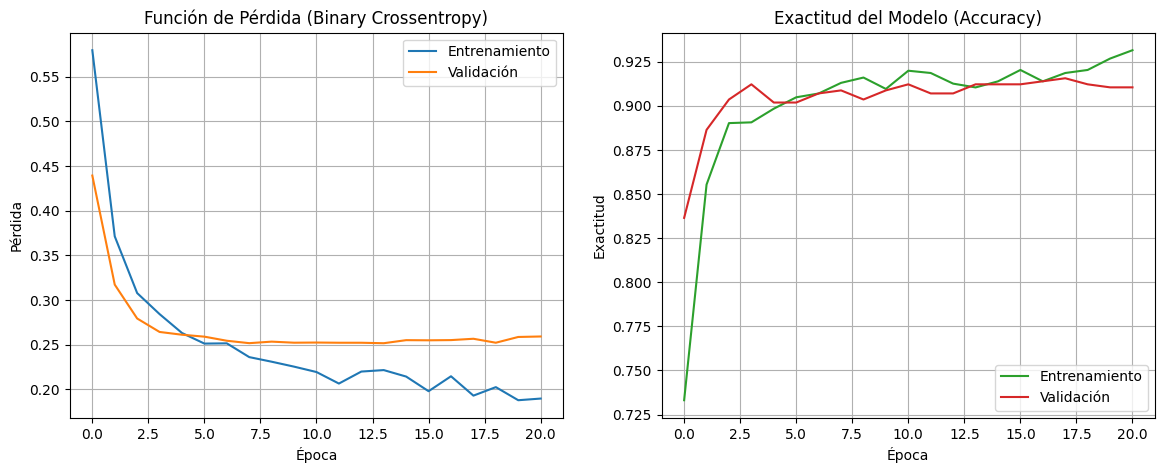

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

=== MATRIZ DE CONFUSIÓN ===
[[226  51]
 [ 20 429]]

=== INFORME DE CLASIFICACIÓN (MÉTRICAS ROBUSTAS) ===
              precision    recall  f1-score   support

 Dropout (0)       0.92      0.82      0.86       277
Graduate (1)       0.89      0.96      0.92       449

    accuracy                           0.90       726
   macro avg       0.91      0.89      0.89       726
weighted avg       0.90      0.90      0.90       726



In [155]:
# 1. Definir la arquitectura de la Red Neuronal
num_caracteristicas = X_train_scaled.shape[1]

model_dropout = Sequential([
    # Capa de Entrada y Primera Capa Oculta
    Dense(64, activation='relu', input_shape=(num_caracteristicas,), name="Capa_Entrada_Oculta1"),
    Dropout(0.3, name="Dropout_1"), # Apaga aleatoriamente el 30% de las neuronas para evitar overfitting

    # Segunda Capa Oculta
    Dense(32, activation='relu', name="Capa_Oculta2"),
    Dropout(0.2, name="Dropout_2"),

    # Tercera Capa Oculta
    Dense(16, activation='relu', name="Capa_Oculta3"),

    # Capa de Salida: 1 neurona con Sigmoide para clasificación binaria (0 o 1)
    Dense(1, activation='sigmoid', name="Capa_Salida")
])

# 2. Compilación del Modelo
model_dropout.compile(
    optimizer='adam',
    loss='binary_crossentropy', # Función de pérdida ideal para clasificación binaria
    metrics=['accuracy']
)

# 3. Early Stopping para detener el entrenamiento si la pérdida de validación deja de mejorar
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

# 4. Entrenamiento del modelo (Fitting)
print("Iniciando el entrenamiento de la Red Neuronal...")
history = model_dropout.fit(
    X_train_scaled, y_train,
    epochs=60,
    batch_size=32,
    validation_split=0.2, # 20% para monitoreo en tiempo de entrenamiento
    callbacks=[early_stop],
    verbose=1
)

# =====================================================================
# PASO 4: Evaluación y Métricas
# =====================================================================

# 1. Graficar curvas de aprendizaje (Loss y Accuracy)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida
ax1.plot(history.history['loss'], label='Entrenamiento', color='tab:blue')
ax1.plot(history.history['val_loss'], label='Validación', color='tab:orange')
ax1.set_title('Función de Pérdida (Binary Crossentropy)')
ax1.set_xlabel('Época')
ax1.set_ylabel('Pérdida')
ax1.legend()
ax1.grid(True)

# Gráfico de Exactitud
ax2.plot(history.history['accuracy'], label='Entrenamiento', color='tab:green')
ax2.plot(history.history['val_accuracy'], label='Validación', color='tab:red')
ax2.set_title('Exactitud del Modelo (Accuracy)')
ax2.set_xlabel('Época')
ax2.set_ylabel('Exactitud')
ax2.legend()
ax2.grid(True)
plt.show()

# 2. Realizar predicciones en el conjunto de prueba (Test) nunca antes visto
y_pred_probs = model_dropout.predict(X_test_scaled)
y_pred_classes = (y_pred_probs > 0.5).astype(int).flatten()

# 3. Matriz de Confusión e Informe de Clasificación
print("\n=== MATRIZ DE CONFUSIÓN ===")
print(confusion_matrix(y_test, y_pred_classes))

print("\n=== INFORME DE CLASIFICACIÓN (MÉTRICAS ROBUSTAS) ===")
print(classification_report(y_test, y_pred_classes, target_names=['Dropout (0)', 'Graduate (1)']))

# **PASO 5: Despliegue Streamlit**

In [127]:
# Instalar streamlit para la app y pyngrok para crear el túnel de comunicación
!pip install pyngrok --quiet

In [128]:
%pip install streamlit pandas plotly folium streamlit-folium

In [129]:
# Pega tu authtoken de ngrok aquí para autenticar tu sesión
!ngrok config add-authtoken 3L1dm8rkuNAaCoZpFfGdjSNWZXH_5BYtpTJadEveMi3HHZ9Gb #PEGAR TOKEN AQUI

Authtoken already set in configuration file: /root/.config/ngrok/ngrok.yml


In [130]:
# --- Paso Final: Ejecutar Servidor y Crear Túnel en un Solo Paso ---
from pyngrok import ngrok
import time

# El truco clave: '&>/dev/null &' envía el proceso al fondo Y silencia su salida de texto
# para que no bloquee la celda.
!streamlit run app.py --server.headless true --server.enableCORS false --server.address=0.0.0.0 &>/dev/null &

# Le damos unos segundos al servidor para que se despierte
print("⏳ Iniciando el servidor de Streamlit en segundo plano...")
time.sleep(5)

# Ahora que el servidor está corriendo en el fondo, creamos el túnel con ngrok
print("🚇 Creando el túnel público con ngrok...")
public_url = ngrok.connect(addr="8501")
print(f"🎉 ¡Aplicación lista! Haz clic en esta URL para abrirla: {public_url}")

⏳ Iniciando el servidor de Streamlit en segundo plano...
🚇 Creando el túnel público con ngrok...
🎉 ¡Aplicación lista! Haz clic en esta URL para abrirla: NgrokTunnel: "https://huntsman-cattishly-vitamins.ngrok-free.dev" -> "http://localhost:8501"


In [156]:
%%writefile app.py
import streamlit as st
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Importaciones de TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Configuración de página
st.set_page_config(page_title="Predicción Deserción Universitaria", layout="wide")

# Título principal de la aplicación
st.title("Sistema de Predicción de Deserción Universitaria")
st.markdown("### Enfoque Actualizado: Red Neuronal con Regularización Dropout")

# --- CARGA Y PREPROCESAMIENTO DE DATOS EN CACHÉ ---
@st.cache_data
def load_and_clean_data():
    try:
        data = pd.read_csv('data.csv', sep=';')
    except FileNotFoundError:
        st.error("No se encontró el archivo 'data.csv'. Por favor, colócalo en el mismo directorio.")
        st.stop()

    # Limpieza de nombres de columnas
    data.columns = data.columns.str.strip()

    # Excluir a los estudiantes 'Enrolled'
    data = data[data['Target'] != 'Enrolled'].copy()

    # Mapa de conversión binario limpio (Graduate = 1, Dropout = 0)
    data['Target_Binario'] = data['Target'].map({'Graduate': 1, 'Dropout': 0}).astype(int)
    return data

data = load_and_clean_data()

# Separar características (X) y etiqueta (y)
X = data.drop(columns=['Target', 'Target_Binario'])
y = data['Target_Binario']

# Dividir en entrenamiento y prueba de manera fija (Idéntico al script)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalar los datos
@st.cache_resource
def scale_data(X_train, X_test):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    return scaler, X_train_scaled, X_test_scaled

scaler, X_train_scaled, X_test_scaled = scale_data(X_train, X_test)

# --- CARGA O ENTRENAMIENTO DEL MODELO NEURONAL ---
@st.cache_resource
def get_neural_network_model(_X_train_scaled, _y_train):
    model_path = 'modelo_dropout.keras'
    history_path = 'historial_modelo.json'

    class LoadedHistory:
        def __init__(self, history_dict):
            self.history = history_dict

    # Forzar la carga si los archivos del script ya existen en la carpeta
    if os.path.exists(model_path) and os.path.exists(history_path):
        model = load_model(model_path)
        with open(history_path, 'r') as f:
            history_dict = json.load(f)
        history = LoadedHistory(history_dict)
    else:
        # Configuración de contingencia si no se encuentra el archivo pre-entrenado
        num_caracteristicas = _X_train_scaled.shape[1]
        model = Sequential([
            Dense(64, activation='relu', input_shape=(num_caracteristicas,), name="Capa_Entrada_Oculta1"),
            Dropout(0.3, name="Dropout_1"),
            Dense(32, activation='relu', name="Capa_Oculta2"),
            Dropout(0.2, name="Dropout_2"),
            Dense(16, activation='relu', name="Capa_Oculta3"),
            Dense(1, activation='sigmoid', name="Capa_Salida")
        ])

        model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
        early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

        fit_history = model.fit(
            _X_train_scaled, _y_train,
            epochs=60, batch_size=32,
            validation_split=0.2, callbacks=[early_stop], verbose=0
        )

        model.save(model_path)
        with open(history_path, 'w') as f:
            json.dump(fit_history.history, f)

        history = LoadedHistory(fit_history.history)

    return model, history

model_dropout, history = get_neural_network_model(X_train_scaled, y_train)

# --- BARRA LATERAL (NAVEGACIÓN) ---
st.sidebar.header("Menú de Navegación")
menu = st.sidebar.selectbox(
    "Selecciona la funcionalidad",
    ["Exploración (EDA)", "Predicción Interactiva Neuronal", "Evaluación y Métricas"]
)
st.sidebar.markdown("---")
st.sidebar.markdown("**EQUIPO DE TRABAJO:**")
st.sidebar.markdown(
    "1. Hinsna Jurany Rincon Guerrero\n"
    "2. Ruth Catherin Rincon Guerrero\n"
    "3. Deivy Steve Varon Corredor\n"
    "4. Julio Andrés Silva Aragón\n"
    "5. Rigo Arvey Chapid Guacales"
)

# --- PANEL 1: EXPLORACIÓN (EDA) ---
if menu == "Exploración (EDA)":
    st.header("1. Análisis Exploratorio de Datos (EDA)")
    col1, col2 = st.columns(2)
    with col1:
        st.subheader("Distribución de la Edad al Matricularse")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.histplot(data=data, x='Age at enrollment', hue='Target', multiple='stack', bins=30, palette='viridis', ax=ax)
        ax.set_xlabel('Edad al Matricularse (Age at enrollment)')
        ax.set_ylabel('Cantidad de Estudiantes')
        st.pyplot(fig)
        st.caption("Conclusión: El riesgo de abandono escolar se incrementa exponencialmente a mayor edad de inscripción.")
    with col2:
        st.subheader("Calificaciones del 2do Semestre")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.boxplot(data=data, x='Target', y='Curricular units 2nd sem (grade)', palette='Pastel1', ax=ax)
        ax.set_xlabel('Estado Final')
        ax.set_ylabel('Nota Promedio (2do Semestre)')
        st.pyplot(fig)
        st.caption("Conclusión: Los estudiantes que abandonan suelen acumular notas promedio cercanas a cero.")

# --- PANEL 2: PREDICCIÓN INTERACTIVA NEURONAL ---
elif menu == "Predicción Interactiva Neuronal":
    st.header("2. Módulo de Predicción con Red Neuronal Profunda")
    st.write("La evaluación se procesa mediante una arquitectura secuencial con capas densas y regularización Dropout.")
    col1, col2, col3 = st.columns(3)
    with col1:
        age = st.number_input("Edad al matricularse (Age at enrollment):", min_value=10, max_value=70, value=20)
        gender = st.selectbox("Género (Gender):", options=[0, 1], format_func=lambda x: "Femenino" if x == 0 else "Masculino")
        scholarship = st.selectbox("¿Tiene beca? (Scholarship holder):", options=[0, 1], format_func=lambda x: "No" if x == 0 else "Sí")
    with col2:
        tuition = st.selectbox("¿Matrícula al día? (Tuition fees up to date):", options=[0, 1], format_func=lambda x: "No" if x == 0 else "Sí")
        debtor = st.selectbox("¿Es deudor? (Debtor):", options=[0, 1], format_func=lambda x: "No" if x == 0 else "Sí")
        admission_grade = st.slider("Nota de admisión (Admission grade):", min_value=0.0, max_value=200.0, value=130.0, step=0.1)
    with col3:
        enrolled_2nd = st.number_input("Unidades curriculares inscritas 2° sem:", min_value=0, max_value=30, value=6)
        approved_2nd = st.number_input("Unidades curriculares aprobadas 2° sem:", min_value=0, max_value=30, value=5)
        grade_2nd = st.slider("Nota promedio 2° semestre:", min_value=0.0, max_value=20.0, value=12.0, step=0.1)

    if st.button("Procesar por Red Neuronal"):
        input_data = X.mean().to_frame().T
        input_data['Age at enrollment'] = age
        input_data['Gender'] = gender
        input_data['Scholarship holder'] = scholarship
        input_data['Tuition fees up to date'] = tuition
        input_data['Debtor'] = debtor
        input_data['Admission grade'] = admission_grade
        input_data['Curricular units 2nd sem (enrolled)'] = enrolled_2nd
        input_data['Curricular units 2nd sem (approved)'] = approved_2nd
        input_data['Curricular units 2nd sem (grade)'] = grade_2nd

        input_scaled = scaler.transform(input_data)
        prob = model_dropout.predict(input_scaled)[0][0]
        pred_class = 1 if prob > 0.5 else 0
        st.markdown("---")
        if pred_class == 1:
            st.success(f"### Estado Predicho por Red Neuronal: **GRADUADO (Graduate)**")
            st.metric(label="Probabilidad de éxito académico (Salida Sigmoide)", value=f"{prob*100:.2f}%")
        else:
            st.error(f"### Estado Predicho por Red Neuronal: **DESERCIÓN (Dropout)**")
            st.metric(label="Probabilidad de deserción estimada", value=f"{(1-prob)*100:.2f}%")

# --- PANEL 3: EVALUACIÓN Y MÉTRICAS ---
elif menu == "Evaluación y Métricas":
    st.header("3. Curvas de Aprendizaje y Robustez del Modelo Neuronal")
    st.write("Análisis detallado de la convergencia (Loss y Accuracy) y distribución del error.")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['loss'], label='Entrenamiento', color='tab:blue', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Validación', color='tab:orange', linewidth=2)
    ax1.set_title('Función de Pérdida (Binary Crossentropy)')
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Pérdida')
    ax1.legend()
    ax1.grid(True)

    ax2.plot(history.history['accuracy'], label='Entrenamiento', color='tab:green', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Validación', color='tab:red', linewidth=2)
    ax2.set_title('Exactitud del Modelo (Accuracy)')
    ax2.set_xlabel('Época')
    ax2.set_ylabel('Exactitud')
    ax2.legend()
    ax2.grid(True)
    st.pyplot(fig)

    # Inferencia en el Set de Test
    y_pred_probs = model_dropout.predict(X_test_scaled)
    y_pred_classes = (y_pred_probs > 0.5).astype(int).flatten()

    # SECCIÓN CORREGIDA CON INDENTACIÓN ADECUADA
    col_metrics1, col_metrics2 = st.columns(2)
    with col_metrics1:
        st.subheader("Matriz de Confusión en Test")
        cm_neural = confusion_matrix(y_test, y_pred_classes)
        fig_cm, ax_cm = plt.subplots(figsize=(5, 4))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm_neural, display_labels=['Dropout (0)', 'Graduate (1)'])
        disp.plot(cmap=plt.cm.Purples, ax=ax_cm, values_format='d')
        st.pyplot(fig_cm)
    with col_metrics2:
        st.subheader("Informe de Clasificación Robustas")
        report_dict = classification_report(y_test, y_pred_classes, target_names=['Dropout (0)', 'Graduate (1)'], output_dict=True)
        report_df = pd.DataFrame(report_dict).transpose()
        st.dataframe(report_df.style.format("{:.2f}"))
        accuracy_global = report_dict['accuracy']
        st.metric(label="Exactitud Global de la Red Neuronal (Test Accuracy)", value=f"{accuracy_global*100:.2f}%")

Overwriting app.py
